# AgroSmart Puno
**Proyecto Sello — Equipo Innov8**
Integrantes: Jose Armando Mamani Poccohuanca, Mijael Yurins Coaquira Justo
Docente: Abel Angel Sullon Macalupu

Este notebook cubre las **4 secciones exigidas por la plantilla de Producto U1**:

1. Arquitectura Big Data seleccionada.
2. Transformaciones distribuidas con PySpark.
3. Calidad de datos y particionamiento analítico.
4. Componente ML distribuido (regresión de Jose + clasificación de Mijael).


In [18]:
from pyspark.sql import SparkSession
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType, TimestampType, BooleanType
from pyspark.sql import functions as F
from pyspark.sql.window import Window
spark.conf.set("spark.sql.debug.maxToStringFields", 1000)

spark = (
    SparkSession.builder
    .appName("agrosmart-puno")
    .master("local[*]")
    .config("spark.ui.port", "4040")
    .getOrCreate()
)

spark

## Carga con esquema explícito y filtrado al alcance (Puno)

Antes de las 4 secciones, se carga con `StructType` (sin dejar que Spark infiera el tipo) y se filtra el dataset nacional (120 sensores / 10 regiones) a las **7 estaciones de la región Puno**.

In [19]:
RUTA_CSV_LECTURAS = "file:///opt/solanumtuberosumdata/DATA/lecturas_humedad_suelo.csv"
RUTA_CSV_PERFIL = "file:///opt/solanumtuberosumdata/DATA/perfil_diario_riego_clima.csv"
RUTA_CSV_METADATA = "file:///opt/solanumtuberosumdata/DATA/sensores_metadata.csv"

schema_lecturas = StructType([
    StructField("reading_id", IntegerType(), True),
    StructField("sensor_id", StringType(), True),
    StructField("timestamp", TimestampType(), True),
    StructField("humedad_suelo_pct", DoubleType(), True),
    StructField("temp_suelo_c", DoubleType(), True),
    StructField("temp_aire_c", DoubleType(), True),
    StructField("humedad_aire_pct", DoubleType(), True),
    StructField("lluvia_mm_ultima_hora", DoubleType(), True),
    StructField("bateria_v", DoubleType(), True),
    StructField("señal_dbm", IntegerType(), True),
    StructField("estado_sensor", StringType(), True),
])

schema_perfil = StructType([
    StructField("sensor_id", StringType(), True),
    StructField("fecha", StringType(), True),  # se castea a date abajo
    StructField("etapa_cultivo", StringType(), True),
    StructField("dias_desde_siembra", IntegerType(), True),
    StructField("humedad_prom_pct", DoubleType(), True),
    StructField("humedad_min_pct", DoubleType(), True),
    StructField("humedad_max_pct", DoubleType(), True),
    StructField("lluvia_mm", DoubleType(), True),
    StructField("riego_aplicado", BooleanType(), True),
    StructField("volumen_riego_l", DoubleType(), True),
    StructField("evapotranspiracion_mm", DoubleType(), True),
    StructField("alerta", StringType(), True),
])

schema_metadata = StructType([
    StructField("sensor_id", StringType(), True),
    StructField("nombre_estacion", StringType(), True),
    StructField("region", StringType(), True),
    StructField("latitud", DoubleType(), True),
    StructField("longitud", DoubleType(), True),
    StructField("altitud_m", IntegerType(), True),
    StructField("cultivo", StringType(), True),
    StructField("tipo_suelo", StringType(), True),
    StructField("profundidad_sensor_cm", IntegerType(), True),
    StructField("marca_sensor", StringType(), True),
    StructField("sistema_riego", StringType(), True),
    StructField("area_parcela_ha", DoubleType(), True),
    StructField("fecha_instalacion", StringType(), True),
])

df_lecturas = spark.read.csv(RUTA_CSV_LECTURAS, header=True, schema=schema_lecturas)
df_perfil = spark.read.csv(RUTA_CSV_PERFIL, header=True, schema=schema_perfil).withColumn("fecha", F.to_date("fecha"))
df_metadata = spark.read.csv(RUTA_CSV_METADATA, header=True, schema=schema_metadata)

df_metadata_puno = df_metadata.filter(F.col("region") == "Puno")
sensores_puno = [r["sensor_id"] for r in df_metadata_puno.select("sensor_id").collect()]

df_lecturas_puno = df_lecturas.join(F.broadcast(df_metadata_puno.select("sensor_id", "cultivo", "altitud_m", "tipo_suelo", "sistema_riego")), on="sensor_id", how="inner")
df_perfil_puno = df_perfil.join(F.broadcast(df_metadata_puno.select("sensor_id", "cultivo", "altitud_m", "tipo_suelo", "sistema_riego")), on="sensor_id", how="inner")

print("Estaciones de Puno:", sensores_puno)
print("lecturas Puno:", df_lecturas_puno.count(), "filas |", "perfil Puno:", df_perfil_puno.count(), "filas")
df_metadata_puno.select("sensor_id", "nombre_estacion", "cultivo", "altitud_m", "tipo_suelo", "sistema_riego", "area_parcela_ha").show(truncate=False)

Estaciones de Puno: ['SEN-0001', 'SEN-0008', 'SEN-0076', 'SEN-0084', 'SEN-0086', 'SEN-0098', 'SEN-0106']
lecturas Puno: 1349 filas | perfil Puno: 1295 filas
+---------+------------------+-------+---------+--------------+----------------+---------------+
|sensor_id|nombre_estacion   |cultivo|altitud_m|tipo_suelo    |sistema_riego   |area_parcela_ha|
+---------+------------------+-------+---------+--------------+----------------+---------------+
|SEN-0001 |Estacion_Puno_0001|Maíz   |2974     |Arenoso       |Gravedad        |11.83          |
|SEN-0008 |Estacion_Puno_0008|Alfalfa|3311     |Franco-arenoso|Goteo           |1.9            |
|SEN-0076 |Estacion_Puno_0076|Alfalfa|3570     |Franco-arenoso|Ninguno (secano)|7.67           |
|SEN-0084 |Estacion_Puno_0084|Papa   |3481     |Arenoso       |Goteo           |1.82           |
|SEN-0086 |Estacion_Puno_0086|Palta  |168      |Arcilloso     |Goteo           |6.14           |
|SEN-0098 |Estacion_Puno_0098|Trigo  |1746     |Arenoso       |Gote

## 1. Arquitectura Big Data seleccionada

**Arquitectura: Lambda.** Justificación: AgroSmart Puno necesita histórico (perfil diario, para reportes y para entrenar los modelos batch. **y** tiempo real (lecturas horarias, para alertas en vivo) — ambos como sistemas separados que convergen en un solo tablero, por eso Lambda y no Kappa.


**Tabla 1. Ficha de arquitectura (resumen)**

| Campo | Detalle |
|---|---|
| Tipo de procesamiento | Ambos — batch (perfil diario) y streaming (lecturas horarias) |
| Arquitectura | Lambda |
| Ingesta | Kafka (Unidad II) |
| Procesamiento batch | PySpark — este notebook (secciones 2 a 4) |
| Procesamiento streaming | Spark Structured Streaming (Unidad II) |
| Almacenamiento | Parquet particionado (sección 3) |
| Visualización | Notebook (U1, tablas/gráficos) + Grafana (U2) |
| Riesgo principal | Nulos en variables críticas (`humedad_suelo_pct`, `evapotranspiracion_mm`) si no se tratan antes del modelo (ver sección 3) |


## 2. Transformaciones distribuidas con PySpark

Extracción ya hecha (con esquema explícito). Se aplican ahora: una transformación con `withColumn()`/`filter()`, una agrupación con `groupBy().agg()`, una operación RDD, y la verificación del plan de ejecución (`explain(True)`).

In [20]:
# Transformación: categoría de humedad y bandera de estrés hídrico por lectura
df_lecturas_transformado = (
    df_lecturas_puno
    .withColumn(
        "categoria_humedad",
        F.when(F.col("humedad_suelo_pct") < 15, "DEFICIT")
         .when(F.col("humedad_suelo_pct") > 35, "SATURACION")
         .otherwise("NORMAL")
    )
    .withColumn("es_lectura_valida", F.when(F.col("estado_sensor") == "OK", F.lit(True)).otherwise(F.lit(False)))
    .filter(F.col("humedad_suelo_pct").isNotNull())
)

df_lecturas_transformado.select("sensor_id", "timestamp", "humedad_suelo_pct", "categoria_humedad", "es_lectura_valida").show(8, truncate=False)

+---------+-------------------+-----------------+-----------------+-----------------+
|sensor_id|timestamp          |humedad_suelo_pct|categoria_humedad|es_lectura_valida|
+---------+-------------------+-----------------+-----------------+-----------------+
|SEN-0001 |2026-06-01 00:00:00|18.25            |NORMAL           |true             |
|SEN-0001 |2026-06-01 01:00:00|19.15            |NORMAL           |true             |
|SEN-0001 |2026-06-01 02:00:00|19.05            |NORMAL           |true             |
|SEN-0001 |2026-06-01 03:00:00|19.49            |NORMAL           |true             |
|SEN-0001 |2026-06-01 04:00:00|19.26            |NORMAL           |true             |
|SEN-0001 |2026-06-01 05:00:00|18.96            |NORMAL           |true             |
|SEN-0001 |2026-06-01 06:00:00|19.83            |NORMAL           |true             |
|SEN-0001 |2026-06-01 07:00:00|19.53            |NORMAL           |true             |
+---------+-------------------+-----------------+-----

In [21]:
# Agrupación / agregación: humedad promedio y conteo de lecturas por categoría y estación
tabla_categoria_estacion = (
    df_lecturas_transformado
    .groupBy("sensor_id", "categoria_humedad")
    .agg(
        F.count("*").alias("n_lecturas"),
        F.round(F.avg("humedad_suelo_pct"), 2).alias("humedad_prom"),
        F.round(F.avg("temp_suelo_c"), 2).alias("temp_suelo_prom"),
    )
    .orderBy("sensor_id", "categoria_humedad")
)

tabla_categoria_estacion.show(30, truncate=False)
pdf_categoria_estacion = tabla_categoria_estacion.toPandas()
pdf_categoria_estacion

+---------+-----------------+----------+------------+---------------+
|sensor_id|categoria_humedad|n_lecturas|humedad_prom|temp_suelo_prom|
+---------+-----------------+----------+------------+---------------+
|SEN-0001 |DEFICIT          |175       |-108.73     |20.23          |
|SEN-0001 |NORMAL           |17        |17.82       |18.33          |
|SEN-0008 |DEFICIT          |174       |-50.95      |15.37          |
|SEN-0008 |NORMAL           |17        |16.81       |14.74          |
|SEN-0076 |DEFICIT          |129       |6.89        |19.81          |
|SEN-0076 |NORMAL           |64        |22.04       |19.62          |
|SEN-0084 |DEFICIT          |179       |4.92        |17.3           |
|SEN-0084 |NORMAL           |10        |18.73       |15.12          |
|SEN-0086 |DEFICIT          |100       |7.89        |21.13          |
|SEN-0086 |NORMAL           |81        |23.7        |20.9           |
|SEN-0086 |SATURACION       |10        |48.07       |18.8           |
|SEN-0098 |DEFICIT  

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,sensor_id,categoria_humedad,n_lecturas,humedad_prom,temp_suelo_prom
0,SEN-0001,DEFICIT,175,-108.73,20.23
1,SEN-0001,NORMAL,17,17.82,18.33
2,SEN-0008,DEFICIT,174,-50.95,15.37
3,SEN-0008,NORMAL,17,16.81,14.74
4,SEN-0076,DEFICIT,129,6.89,19.81
5,SEN-0076,NORMAL,64,22.04,19.62
6,SEN-0084,DEFICIT,179,4.92,17.30
7,SEN-0084,NORMAL,10,18.73,15.12
8,SEN-0086,DEFICIT,100,7.89,21.13
9,SEN-0086,NORMAL,81,23.70,20.90


In [22]:
!pip install matplotlib


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


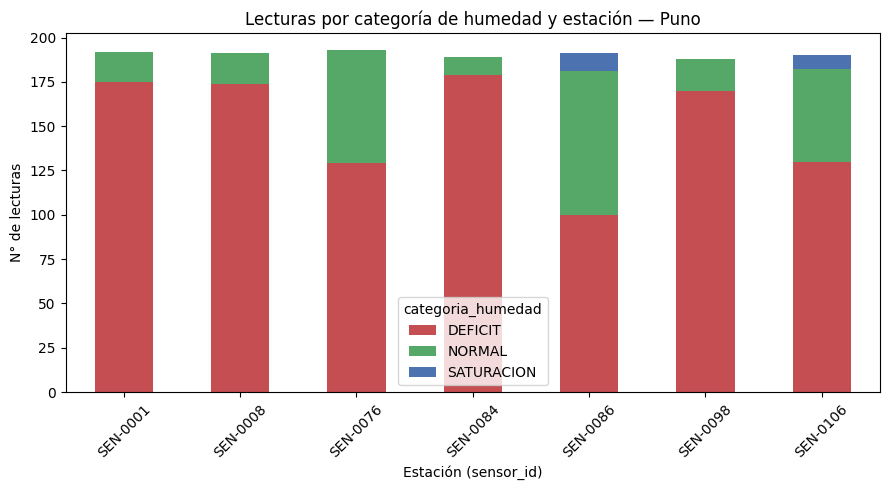

In [23]:
# Gráfico: distribución de categorías de humedad por estación (tabla anterior)
import matplotlib.pyplot as plt

pivot_cat = pdf_categoria_estacion.pivot(index="sensor_id", columns="categoria_humedad", values="n_lecturas").fillna(0)

fig, ax = plt.subplots(figsize=(9, 5))
pivot_cat.plot(kind="bar", stacked=True, ax=ax, color={"DEFICIT": "#C44E52", "NORMAL": "#55A868", "SATURACION": "#4C72B0"})
ax.set_title("Lecturas por categoría de humedad y estación — Puno")
ax.set_ylabel("N° de lecturas")
ax.set_xlabel("Estación (sensor_id)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("categorias_humedad_por_estacion.png", dpi=110)
plt.show()

In [24]:
# Operación RDD: promedio de humedad por estación calculado con map/reduceByKey
rdd_humedad = (
    df_lecturas_transformado
    .select("sensor_id", "humedad_suelo_pct")
    .rdd.map(lambda row: (row["sensor_id"], (row["humedad_suelo_pct"], 1)))
)

rdd_sumas = rdd_humedad.reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
rdd_promedios = rdd_sumas.mapValues(lambda x: round(x[0] / x[1], 2)).sortByKey()

for sensor, promedio in rdd_promedios.collect():
    print(f"{sensor}: humedad promedio = {promedio}%")

SEN-0001: humedad promedio = -97.53%
SEN-0008: humedad promedio = -44.92%
SEN-0076: humedad promedio = 11.91%
SEN-0084: humedad promedio = 5.65%
SEN-0086: humedad promedio = 16.7%
SEN-0098: humedad promedio = 7.74%
SEN-0106: humedad promedio = 12.68%


In [25]:
# Verificación del plan de ejecución — evidencia de que Spark ejecuta recién aquí (lazy evaluation)
df_lecturas_transformado.groupBy("sensor_id").agg(F.avg("humedad_suelo_pct")).explain(True)

== Parsed Logical Plan ==
'Aggregate ['sensor_id], ['sensor_id, unresolvedalias('avg('humedad_suelo_pct))]
+- Filter isnotnull(humedad_suelo_pct#1623)
   +- Project [sensor_id#1621, reading_id#1620, timestamp#1622, humedad_suelo_pct#1623, temp_suelo_c#1624, temp_aire_c#1625, humedad_aire_pct#1626, lluvia_mm_ultima_hora#1627, bateria_v#1628, señal_dbm#1629, estado_sensor#1630, cultivo#1651, altitud_m#1650, tipo_suelo#1652, sistema_riego#1655, categoria_humedad#1737, CASE WHEN (estado_sensor#1630 = OK) THEN true ELSE false END AS es_lectura_valida#1738]
      +- Project [sensor_id#1621, reading_id#1620, timestamp#1622, humedad_suelo_pct#1623, temp_suelo_c#1624, temp_aire_c#1625, humedad_aire_pct#1626, lluvia_mm_ultima_hora#1627, bateria_v#1628, señal_dbm#1629, estado_sensor#1630, cultivo#1651, altitud_m#1650, tipo_suelo#1652, sistema_riego#1655, CASE WHEN (humedad_suelo_pct#1623 < cast(15 as double)) THEN DEFICIT WHEN (humedad_suelo_pct#1623 > cast(35 as double)) THEN SATURACION ELSE NOR

## 3. Calidad de datos y particionamiento analítico

Controles mínimos exigibles: esquema explícito (ya aplicado), **validación de rango**, duplicados, nulos, particionamiento en Parquet, y verificación de ida y vuelta.

### 3.1 Validación de rango códigos de error del sensor

In [26]:
rango_invalido = df_lecturas_puno.filter((F.col("humedad_suelo_pct") < 0) | (F.col("humedad_suelo_pct") > 100))
print("Lecturas fuera de rango físico (< 0% o > 100%) en Puno:", rango_invalido.count())
rango_invalido.select("sensor_id", "timestamp", "humedad_suelo_pct").show(truncate=False)

df_lecturas_puno = df_lecturas_puno.withColumn(
    "humedad_suelo_pct",
    F.when((F.col("humedad_suelo_pct") < 0) | (F.col("humedad_suelo_pct") > 100), None).otherwise(F.col("humedad_suelo_pct"))
)

Lecturas fuera de rango físico (< 0% o > 100%) en Puno: 4
+---------+-------------------+-----------------+
|sensor_id|timestamp          |humedad_suelo_pct|
+---------+-------------------+-----------------+
|SEN-0001 |2026-06-02 12:00:00|-9999.0          |
|SEN-0001 |2026-06-07 17:00:00|-9999.0          |
|SEN-0008 |2026-06-03 14:00:00|-9999.0          |
|SEN-0086 |2026-06-06 04:00:00|150.0            |
+---------+-------------------+-----------------+



### 3.2 Diagnóstico de nulos (antes de tratar)

Incluye los nulos originales del CSV **más** los códigos de error recién convertidos a nulo en 3.1.

In [27]:
def contar_nulos(df_spark, nombre):
    total = df_spark.count()
    conteo = df_spark.select([
        F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df_spark.columns
    ]).toPandas().T
    conteo.columns = ["nulos"]
    conteo["pct_nulos"] = (conteo["nulos"] / total * 100).round(2)
    conteo["fuente"] = nombre
    return conteo[conteo["nulos"] > 0]

nulos_lecturas_antes = contar_nulos(df_lecturas_puno, "lecturas_humedad_suelo")
nulos_perfil_antes = contar_nulos(df_perfil_puno, "perfil_diario_riego_clima")

print("Nulos ANTES — lecturas:")
display(nulos_lecturas_antes) if 'display' in dir() else print(nulos_lecturas_antes)
print("Nulos ANTES — perfil:")
print(nulos_perfil_antes)

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Nulos ANTES — lecturas:
                   nulos  pct_nulos                  fuente
humedad_suelo_pct     19       1.41  lecturas_humedad_suelo
temp_suelo_c          15       1.11  lecturas_humedad_suelo
Nulos ANTES — perfil:
                       nulos  pct_nulos                     fuente
evapotranspiracion_mm     18       1.39  perfil_diario_riego_clima


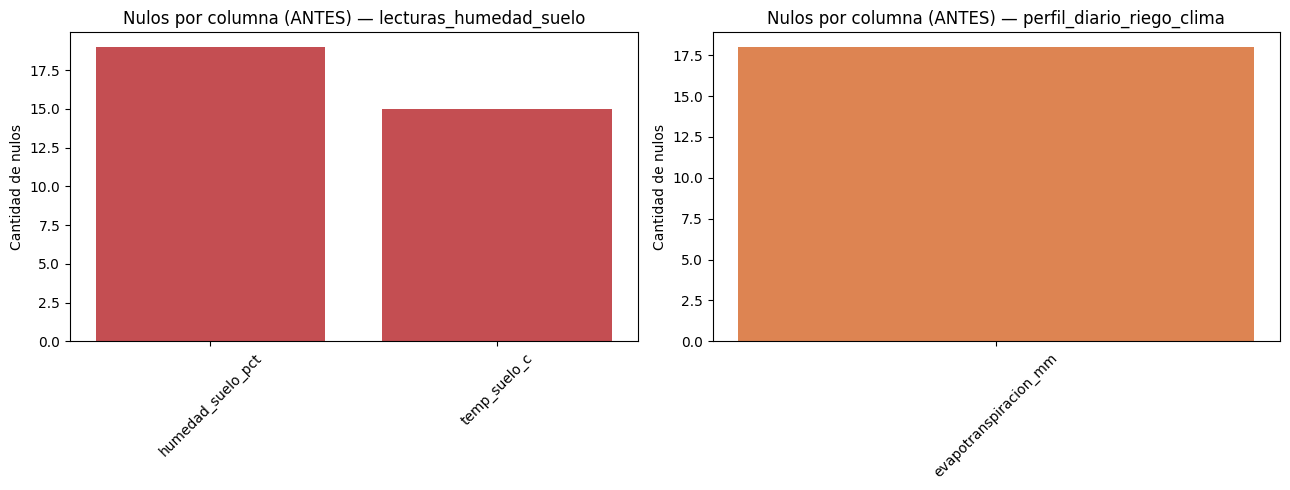

In [28]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(nulos_lecturas_antes.index, nulos_lecturas_antes["nulos"], color="#C44E52")
axes[0].set_title("Nulos por columna (ANTES) — lecturas_humedad_suelo")
axes[0].set_ylabel("Cantidad de nulos")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(nulos_perfil_antes.index, nulos_perfil_antes["nulos"], color="#DD8452")
axes[1].set_title("Nulos por columna (ANTES) — perfil_diario_riego_clima")
axes[1].set_ylabel("Cantidad de nulos")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("nulos_antes.png", dpi=110)
plt.show()

### 3.3 Duplicados

Criterio: en `lecturas_humedad_suelo` una fila es duplicada si repite `sensor_id` + `timestamp` (dos lecturas de la misma estación en la misma hora); en `perfil_diario_riego_clima`, si repite `sensor_id` + `fecha`.

In [29]:
dup_lecturas = df_lecturas_puno.groupBy("sensor_id", "timestamp").count().filter(F.col("count") > 1)
dup_perfil = df_perfil_puno.groupBy("sensor_id", "fecha").count().filter(F.col("count") > 1)

print("Filas duplicadas en lecturas (mismo sensor+hora):", dup_lecturas.count())
print("Filas duplicadas en perfil (mismo sensor+día):", dup_perfil.count())

# Eliminación documentada: se conserva solo una copia por clave (sensor_id + timestamp / fecha)
df_lecturas_dedup = df_lecturas_puno.dropDuplicates(["sensor_id", "timestamp"])
df_perfil_dedup = df_perfil_puno.dropDuplicates(["sensor_id", "fecha"])

print("lecturas: ", df_lecturas_puno.count(), "->", df_lecturas_dedup.count(), "tras dropDuplicates")
print("perfil:   ", df_perfil_puno.count(), "->", df_perfil_dedup.count(), "tras dropDuplicates")

Filas duplicadas en lecturas (mismo sensor+hora): 5
Filas duplicadas en perfil (mismo sensor+día): 0
lecturas:  1349 -> 1344 tras dropDuplicates
perfil:    1295 -> 1295 tras dropDuplicates


### 3.4 Tratamiento de nulos (decisión explícita)

- `humedad_suelo_pct` y `temp_suelo_c` (lecturas): son señales físicas continuas de un sensor — se imputan con el **promedio de esa misma estación** (`Window` por `sensor_id`), no con un promedio global, para no mezclar el nivel base de humedad de una parcela con arena y una con arcilla.
- `evapotranspiracion_mm` (perfil): se imputa con el **promedio de esa misma etapa de cultivo**, porque la evapotranspiración depende directamente de la etapa fenológica.

In [30]:
w_sensor = Window.partitionBy("sensor_id")

df_lecturas_limpio = (
    df_lecturas_dedup
    .withColumn("humedad_suelo_pct", F.coalesce(F.col("humedad_suelo_pct"), F.avg("humedad_suelo_pct").over(w_sensor)))
    .withColumn("temp_suelo_c", F.coalesce(F.col("temp_suelo_c"), F.avg("temp_suelo_c").over(w_sensor)))
)

w_etapa = Window.partitionBy("etapa_cultivo")

df_perfil_limpio = (
    df_perfil_dedup
    .withColumn("evapotranspiracion_mm", F.coalesce(F.col("evapotranspiracion_mm"), F.avg("evapotranspiracion_mm").over(w_etapa)))
)

nulos_lecturas_despues = contar_nulos(df_lecturas_limpio, "lecturas_humedad_suelo")
nulos_perfil_despues = contar_nulos(df_perfil_limpio, "perfil_diario_riego_clima")

print("Nulos DESPUÉS — lecturas:", len(nulos_lecturas_despues), "columnas con nulos")
print("Nulos DESPUÉS — perfil:", len(nulos_perfil_despues), "columnas con nulos")

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Nulos DESPUÉS — lecturas: 0 columnas con nulos
Nulos DESPUÉS — perfil: 0 columnas con nulos


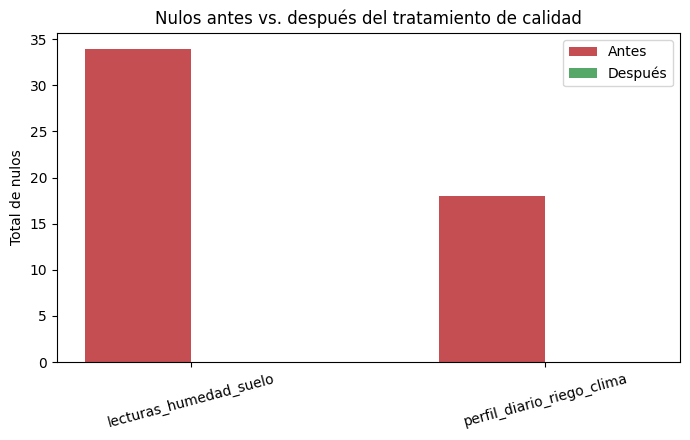

,fuente,nulos_antes,nulos_despues,filas_totales
0,lecturas_humedad_suelo,34,0,1344
1,perfil_diario_riego_clima,18,0,1295


In [31]:
# Tabla comparativa ANTES vs. DESPUÉS del tratamiento de nulos
resumen_calidad = {
    "fuente": ["lecturas_humedad_suelo", "perfil_diario_riego_clima"],
    "nulos_antes": [int(nulos_lecturas_antes["nulos"].sum()), int(nulos_perfil_antes["nulos"].sum())],
    "nulos_despues": [int(nulos_lecturas_despues["nulos"].sum()) if len(nulos_lecturas_despues) else 0,
                       int(nulos_perfil_despues["nulos"].sum()) if len(nulos_perfil_despues) else 0],
}
import pandas as pd
pdf_resumen_calidad = pd.DataFrame(resumen_calidad)
pdf_resumen_calidad["filas_totales"] = [df_lecturas_limpio.count(), df_perfil_limpio.count()]
pdf_resumen_calidad

fig, ax = plt.subplots(figsize=(7, 4.5))
x = range(len(pdf_resumen_calidad))
ax.bar([i - 0.15 for i in x], pdf_resumen_calidad["nulos_antes"], width=0.3, label="Antes", color="#C44E52")
ax.bar([i + 0.15 for i in x], pdf_resumen_calidad["nulos_despues"], width=0.3, label="Después", color="#55A868")
ax.set_xticks(list(x))
ax.set_xticklabels(pdf_resumen_calidad["fuente"], rotation=15)
ax.set_ylabel("Total de nulos")
ax.set_title("Nulos antes vs. después del tratamiento de calidad")
ax.legend()
plt.tight_layout()
plt.savefig("nulos_antes_despues.png", dpi=110)
plt.show()

pdf_resumen_calidad

### 3.5 Particionamiento analítico en Parquet

`perfil_diario_riego_clima` se particiona por `etapa_cultivo` (7 valores, baja cardinalidad, usada en filtros del negocio). `lecturas_humedad_suelo` se particiona por `fecha_lectura` (fecha derivada del timestamp, 8 valores en esta muestra), útil para filtrar por día en los reportes.

In [32]:
df_lecturas_gold = df_lecturas_limpio.withColumn("fecha_lectura", F.to_date("timestamp"))

RUTA_GOLD_LECTURAS = "/opt/solanumtuberosumdata/GOLD/lecturas_humedad_suelo_puno"
RUTA_GOLD_PERFIL = "/opt/solanumtuberosumdata/GOLD/perfil_diario_riego_clima_puno"

(df_lecturas_gold.write.mode("overwrite").partitionBy("fecha_lectura").parquet(RUTA_GOLD_LECTURAS))
(df_perfil_limpio.write.mode("overwrite").partitionBy("etapa_cultivo").parquet(RUTA_GOLD_PERFIL))

print("Escritura Parquet particionada completada.")

Escritura Parquet particionada completada.


### 3.6 Verificación de ida y vuelta

Se lee de vuelta desde Parquet, se reconcilia el conteo de filas y se confirma `PartitionFilters` en el plan de ejecución cuando se filtra por la columna de partición.

In [33]:
df_lecturas_gold_leido = spark.read.parquet(RUTA_GOLD_LECTURAS)
df_perfil_gold_leido = spark.read.parquet(RUTA_GOLD_PERFIL)

print("lecturas escritas:", df_lecturas_gold.count(), "| leídas de vuelta:", df_lecturas_gold_leido.count())
print("perfil escrito:   ", df_perfil_limpio.count(), "| leído de vuelta:", df_perfil_gold_leido.count())

# PartitionFilters esperado en el plan al filtrar por la columna de partición
df_perfil_gold_leido.filter(F.col("etapa_cultivo") == "Floracion").explain(True)

lecturas escritas: 1344 | leídas de vuelta: 1344
perfil escrito:    1295 | leído de vuelta: 1295
== Parsed Logical Plan ==
'Filter '`=`('etapa_cultivo, Floracion)
+- Relation [sensor_id#3984,fecha#3985,dias_desde_siembra#3986,humedad_prom_pct#3987,humedad_min_pct#3988,humedad_max_pct#3989,lluvia_mm#3990,riego_aplicado#3991,volumen_riego_l#3992,evapotranspiracion_mm#3993,alerta#3994,cultivo#3995,altitud_m#3996,tipo_suelo#3997,sistema_riego#3998,etapa_cultivo#3999] parquet

== Analyzed Logical Plan ==
sensor_id: string, fecha: date, dias_desde_siembra: int, humedad_prom_pct: double, humedad_min_pct: double, humedad_max_pct: double, lluvia_mm: double, riego_aplicado: boolean, volumen_riego_l: double, evapotranspiracion_mm: double, alerta: string, cultivo: string, altitud_m: int, tipo_suelo: string, sistema_riego: string, etapa_cultivo: string
Filter (etapa_cultivo#3999 = Floracion)
+- Relation [sensor_id#3984,fecha#3985,dias_desde_siembra#3986,humedad_prom_pct#3987,humedad_min_pct#3988,hu

### 3.7 Panorama general de calidad — tablas y gráficos adicionales

In [34]:
# Tabla resumen: filas por etapa de cultivo y por estación tras la limpieza (perfil Gold)
tabla_resumen_perfil = (
    df_perfil_gold_leido
    .groupBy("etapa_cultivo")
    .agg(
        F.count("*").alias("n_dias"),
        F.round(F.avg("humedad_prom_pct"), 2).alias("humedad_prom"),
        F.round(F.avg("evapotranspiracion_mm"), 2).alias("evapotranspiracion_prom"),
        F.sum(F.when(F.col("alerta") == "SATURACION_SUELO", 1).otherwise(0)).alias("dias_con_alerta"),
    )
    .orderBy("etapa_cultivo")
)
pdf_resumen_perfil = tabla_resumen_perfil.toPandas()
pdf_resumen_perfil

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,etapa_cultivo,n_dias,humedad_prom,evapotranspiracion_prom,dias_con_alerta
0,Cosecha,24,28.80,3.78,1
1,Crecimiento vegetativo,193,26.00,3.12,3
2,Emergencia,302,24.32,3.54,12
3,Floracion,175,25.13,2.99,2
4,Fructificacion,175,25.00,3.01,2
5,Maduracion,175,24.68,3.71,2
6,Siembra,251,23.90,3.77,5


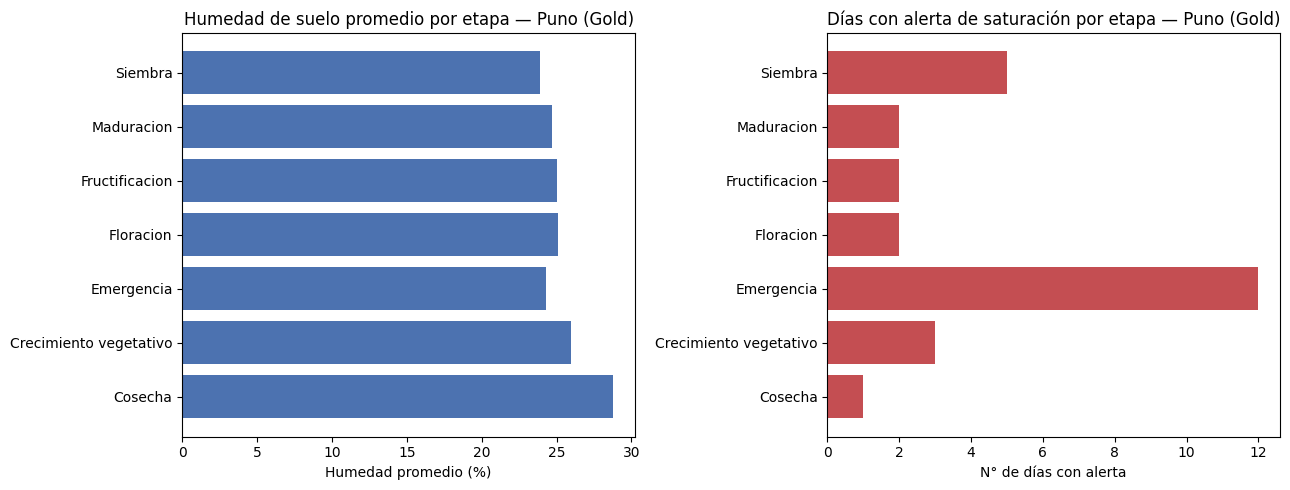

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].barh(pdf_resumen_perfil["etapa_cultivo"], pdf_resumen_perfil["humedad_prom"], color="#4C72B0")
axes[0].set_title("Humedad de suelo promedio por etapa — Puno (Gold)")
axes[0].set_xlabel("Humedad promedio (%)")

axes[1].barh(pdf_resumen_perfil["etapa_cultivo"], pdf_resumen_perfil["dias_con_alerta"], color="#C44E52")
axes[1].set_title("Días con alerta de saturación por etapa — Puno (Gold)")
axes[1].set_xlabel("N° de días con alerta")

plt.tight_layout()
plt.savefig("resumen_perfil_gold.png", dpi=110)
plt.show()

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


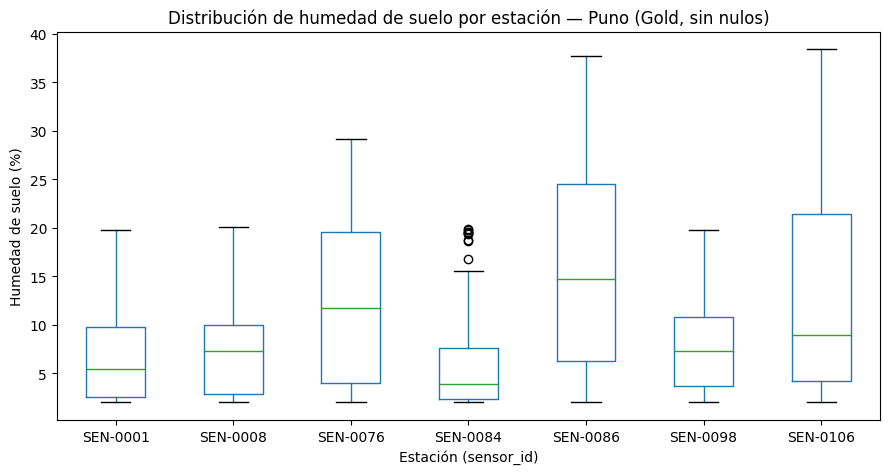

In [36]:
# Boxplot de humedad por estación, ya sobre datos limpios (Gold)
pdf_humedad_gold = df_lecturas_gold_leido.select("sensor_id", "humedad_suelo_pct").toPandas()

fig, ax = plt.subplots(figsize=(9, 5))
pdf_humedad_gold.boxplot(column="humedad_suelo_pct", by="sensor_id", ax=ax, grid=False)
ax.set_title("Distribución de humedad de suelo por estación — Puno (Gold, sin nulos)")
ax.set_xlabel("Estación (sensor_id)")
ax.set_ylabel("Humedad de suelo (%)")
plt.suptitle("")
plt.tight_layout()
plt.savefig("boxplot_humedad_gold.png", dpi=110)
plt.show()

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


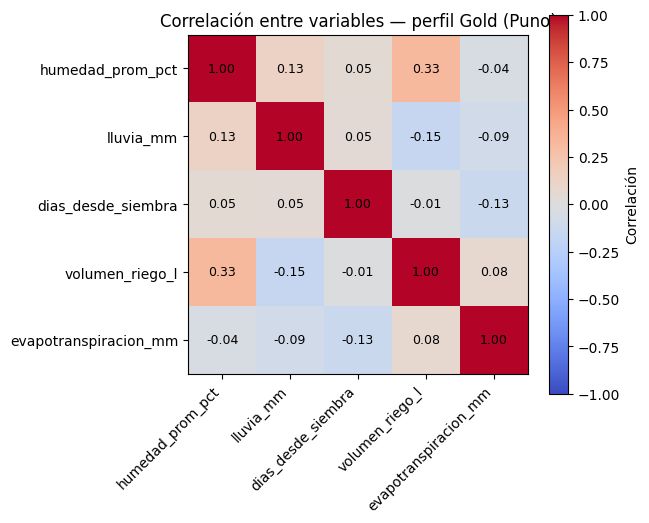

,humedad_prom_pct,lluvia_mm,dias_desde_siembra,volumen_riego_l,evapotranspiracion_mm
humedad_prom_pct,1.000000,0.130427,0.048269,0.327910,-0.040439
lluvia_mm,0.130427,1.000000,0.046242,-0.154675,-0.087914
dias_desde_siembra,0.048269,0.046242,1.000000,-0.013911,-0.132646
volumen_riego_l,0.327910,-0.154675,-0.013911,1.000000,0.077231
evapotranspiracion_mm,-0.040439,-0.087914,-0.132646,0.077231,1.000000


In [37]:
# Matriz de correlación entre variables numéricas del perfil Gold (para orientar el modelo de la sección 4)
cols_numericas = ["humedad_prom_pct", "lluvia_mm", "dias_desde_siembra", "volumen_riego_l", "evapotranspiracion_mm"]
pdf_corr = df_perfil_gold_leido.select(cols_numericas).toPandas().corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(pdf_corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols_numericas))); ax.set_xticklabels(cols_numericas, rotation=45, ha="right")
ax.set_yticks(range(len(cols_numericas))); ax.set_yticklabels(cols_numericas)
for i in range(len(cols_numericas)):
    for j in range(len(cols_numericas)):
        ax.text(j, i, f"{pdf_corr.iloc[i, j]:.2f}", ha="center", va="center", color="black", fontsize=9)
fig.colorbar(im, ax=ax, label="Correlación")
ax.set_title("Correlación entre variables — perfil Gold (Puno)")
plt.tight_layout()
plt.savefig("correlacion_variables.png", dpi=110)
plt.show()

pdf_corr

## 4. Componente ML distribuido

Dos modelos, uno por integrante y por dimensión del Brief:

- **Jose — regresión:** predice `humedad_prom_pct` (humedad de suelo esperada) a partir de lluvia, evapotranspiración, días desde siembra, riego aplicado y etapa de cultivo.
- **Mijael — clasificación:** predice `alerta` (probabilidad de saturación de suelo) a partir de las mismas variables.

Ambos usan `df_perfil_gold_leido` (Gold, ya sin nulos ni duplicados).

### 4.1 Modelo regresión de humedad de suelo esperada

In [38]:
from pyspark.ml.feature import VectorAssembler, StringIndexer
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

indexer_etapa = StringIndexer(inputCol="etapa_cultivo", outputCol="etapa_cultivo_idx")
df_perfil_idx = indexer_etapa.fit(df_perfil_gold_leido).transform(
    df_perfil_gold_leido.withColumn("riego_aplicado_num", F.col("riego_aplicado").cast("int"))
)

features_reg = ["lluvia_mm", "evapotranspiracion_mm", "dias_desde_siembra", "riego_aplicado_num", "etapa_cultivo_idx", "volumen_riego_l"]
assembler_reg = VectorAssembler(inputCols=features_reg, outputCol="features")
df_reg = assembler_reg.transform(df_perfil_idx).select("features", F.col("humedad_prom_pct").alias("label"))

df_train_reg, df_test_reg = df_reg.randomSplit([0.8, 0.2], seed=42)
print("train:", df_train_reg.count(), "| test:", df_test_reg.count())

train: 1045 | test: 250


In [39]:
evaluator_rmse = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
evaluator_r2 = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="r2")
evaluator_mae = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="mae")

# Configuración 1: LinearRegression
lr = LinearRegression(featuresCol="features", labelCol="label")
modelo_lr = lr.fit(df_train_reg)
pred_lr = modelo_lr.transform(df_test_reg)

# Configuración 2: RandomForestRegressor (alternativa a comparar)
rf = RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=100, maxDepth=6, seed=42)
modelo_rf = rf.fit(df_train_reg)
pred_rf = modelo_rf.transform(df_test_reg)

resultados_reg = pd.DataFrame([
    {"modelo": "LinearRegression", "RMSE": evaluator_rmse.evaluate(pred_lr), "R2": evaluator_r2.evaluate(pred_lr), "MAE": evaluator_mae.evaluate(pred_lr)},
    {"modelo": "RandomForestRegressor", "RMSE": evaluator_rmse.evaluate(pred_rf), "R2": evaluator_r2.evaluate(pred_rf), "MAE": evaluator_mae.evaluate(pred_rf)},
]).round(3)

resultados_reg

26/09/11 05:52:15 WARN Instrumentation: [16bbe8a0] regParam is zero, which might cause numerical instability and overfitting.
netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory


,modelo,RMSE,R2,MAE
0,LinearRegression,8.570,0.039,7.478
1,RandomForestRegressor,8.483,0.059,7.251


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


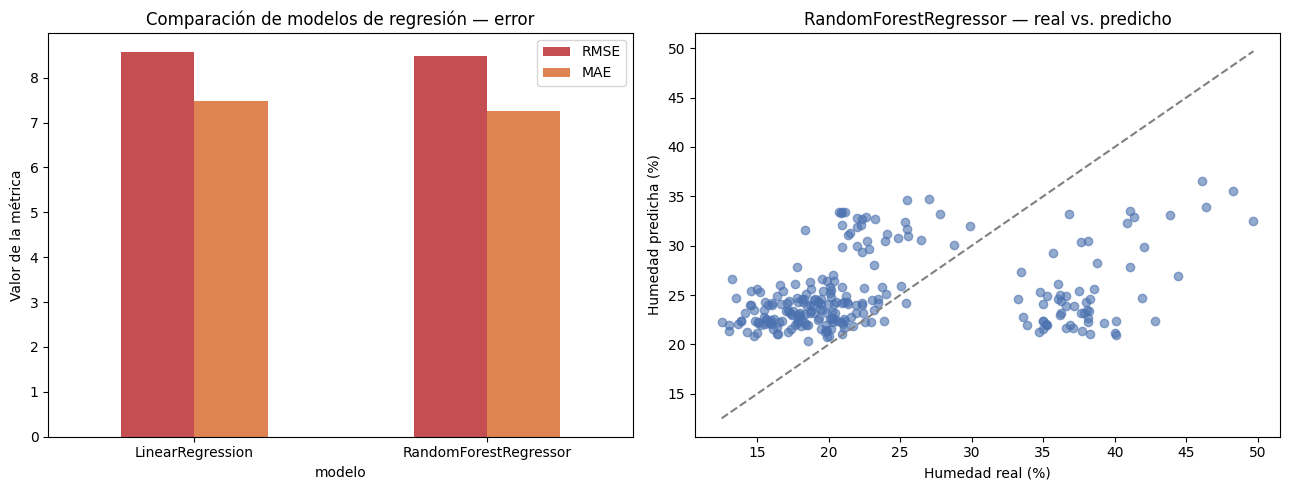

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

resultados_reg.set_index("modelo")[["RMSE", "MAE"]].plot(kind="bar", ax=axes[0], color=["#C44E52", "#DD8452"])
axes[0].set_title("Comparación de modelos de regresión — error")
axes[0].set_ylabel("Valor de la métrica")
axes[0].tick_params(axis="x", rotation=0)

pdf_pred_rf = pred_rf.select("label", "prediction").toPandas()
axes[1].scatter(pdf_pred_rf["label"], pdf_pred_rf["prediction"], alpha=0.6, color="#4C72B0")
lims = [pdf_pred_rf.min().min(), pdf_pred_rf.max().max()]
axes[1].plot(lims, lims, "--", color="gray")
axes[1].set_xlabel("Humedad real (%)")
axes[1].set_ylabel("Humedad predicha (%)")
axes[1].set_title("RandomForestRegressor — real vs. predicho")

plt.tight_layout()
plt.savefig("comparacion_modelos_regresion.png", dpi=110)
plt.show()

Modelo ganador (regresión): RandomForestRegressor


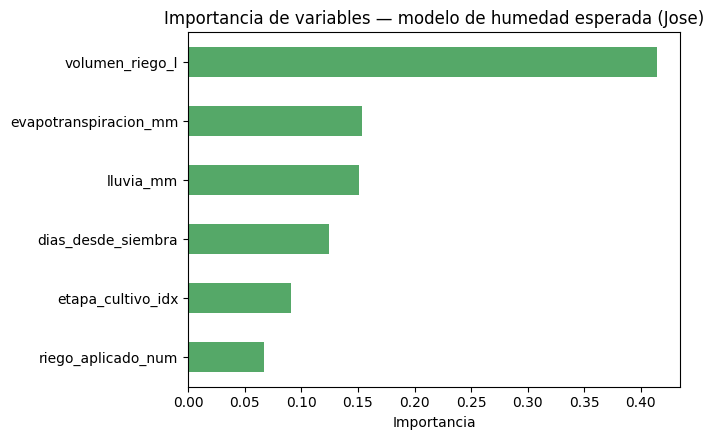

Modelo guardado en /opt/solanumtuberosumdata/MODELOS/


In [41]:
# Importancia de features del modelo ganador (RandomForestRegressor, si su RMSE es menor)
ganador_reg = "RandomForestRegressor" if resultados_reg.set_index("modelo").loc["RandomForestRegressor", "RMSE"] < resultados_reg.set_index("modelo").loc["LinearRegression", "RMSE"] else "LinearRegression"
print("Modelo ganador (regresión):", ganador_reg)

if ganador_reg == "RandomForestRegressor":
    importancias = pd.Series(modelo_rf.featureImportances.toArray(), index=features_reg).sort_values()
    fig, ax = plt.subplots(figsize=(7, 4.5))
    importancias.plot(kind="barh", ax=ax, color="#55A868")
    ax.set_title("Importancia de variables — modelo de humedad esperada (Jose)")
    ax.set_xlabel("Importancia")
    plt.tight_layout()
    plt.savefig("importancia_features_regresion.png", dpi=110)
    plt.show()

modelo_ganador_reg = modelo_rf if ganador_reg == "RandomForestRegressor" else modelo_lr
modelo_ganador_reg.write().overwrite().save("/opt/solanumtuberosumdata/MODELOS/humedad_esperada_" + ganador_reg.lower())
print("Modelo guardado en /opt/solanumtuberosumdata/MODELOS/")

### 4.2 Modelo clasificación de probabilidad de alerta de saturación

**Nota de calidad sobre esta variable objetivo:** en los datos reales de Puno, `alerta = SATURACION_SUELO` ocurre en apenas ~2% de los días (27 de 1,295), frente a ~98% en `NINGUNA` — es un problema de clases fuertemente desbalanceadas, típico de eventos de riesgo poco frecuentes. Por eso se evalúa con `areaUnderROC` y `F1` (no solo `accuracy`, que en un dataset así de desbalanceado sería engañosamente alta incluso si el modelo nunca predijera una alerta), y se documenta el desbalance en vez de ocultarlo.

In [42]:
dist_alerta_puno = df_perfil_gold_leido.groupBy("alerta").count().toPandas()
dist_alerta_puno["pct"] = (dist_alerta_puno["count"] / dist_alerta_puno["count"].sum() * 100).round(2)
print("Distribución real de la variable objetivo (Puno, Gold):")
dist_alerta_puno

Distribución real de la variable objetivo (Puno, Gold):


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,alerta,count,pct
0,NINGUNA,1268,97.92
1,SATURACION_SUELO,27,2.08


In [43]:
from pyspark.ml.feature import VectorAssembler as VA2, StringIndexer as SI2
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

indexer_label = SI2(inputCol="alerta", outputCol="label")
df_perfil_clf_idx = indexer_label.fit(df_perfil_idx).transform(df_perfil_idx)

features_clf = ["lluvia_mm", "evapotranspiracion_mm", "dias_desde_siembra", "riego_aplicado_num", "etapa_cultivo_idx", "volumen_riego_l", "humedad_prom_pct"]
assembler_clf = VA2(inputCols=features_clf, outputCol="features")
df_clf = assembler_clf.transform(df_perfil_clf_idx).select("features", "label")

df_train_clf, df_test_clf = df_clf.randomSplit([0.8, 0.2], seed=42)
print("train:", df_train_clf.count(), "| test:", df_test_clf.count())
print("Distribución de clases (train):")
df_train_clf.groupBy("label").count().show()

train: 1045 | test: 250
Distribución de clases (train):
+-----+-----+
|label|count|
+-----+-----+
|  0.0| 1022|
|  1.0|   23|
+-----+-----+



In [44]:
bin_eval = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
f1_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")
acc_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")

# Configuración 1: LogisticRegression
logr = LogisticRegression(featuresCol="features", labelCol="label")
modelo_logr = logr.fit(df_train_clf)
pred_logr = modelo_logr.transform(df_test_clf)

# Configuración 2: RandomForestClassifier (alternativa a comparar)
rfc = RandomForestClassifier(featuresCol="features", labelCol="label", numTrees=100, maxDepth=6, seed=42)
modelo_rfc = rfc.fit(df_train_clf)
pred_rfc = modelo_rfc.transform(df_test_clf)

resultados_clf = pd.DataFrame([
    {"modelo": "LogisticRegression", "AUC": bin_eval.evaluate(pred_logr), "F1": f1_eval.evaluate(pred_logr), "Accuracy": acc_eval.evaluate(pred_logr)},
    {"modelo": "RandomForestClassifier", "AUC": bin_eval.evaluate(pred_rfc), "F1": f1_eval.evaluate(pred_rfc), "Accuracy": acc_eval.evaluate(pred_rfc)},
]).round(3)

resultados_clf

,modelo,AUC,F1,Accuracy
0,LogisticRegression,1.0,0.996,0.996
1,RandomForestClassifier,1.0,1.000,1.000


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


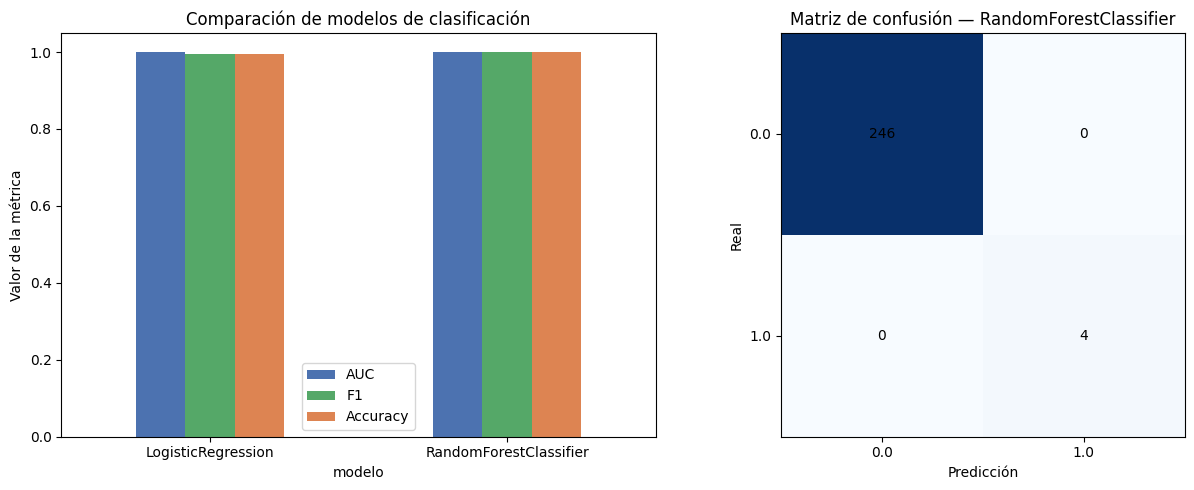

prediction,0.0,1.0
label,,
0.0,246.0,0.0
1.0,0.0,4.0


In [45]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

resultados_clf.set_index("modelo")[["AUC", "F1", "Accuracy"]].plot(kind="bar", ax=axes[0], color=["#4C72B0", "#55A868", "#DD8452"])
axes[0].set_title("Comparación de modelos de clasificación")
axes[0].set_ylabel("Valor de la métrica")
axes[0].tick_params(axis="x", rotation=0)
axes[0].set_ylim(0, 1.05)

# Matriz de confusión del modelo ganador candidato (RandomForestClassifier)
pdf_conf = pred_rfc.groupBy("label", "prediction").count().toPandas()
matriz = pdf_conf.pivot(index="label", columns="prediction", values="count").fillna(0)
im = axes[1].imshow(matriz, cmap="Blues")
axes[1].set_xticks(range(len(matriz.columns))); axes[1].set_xticklabels(matriz.columns)
axes[1].set_yticks(range(len(matriz.index))); axes[1].set_yticklabels(matriz.index)
axes[1].set_xlabel("Predicción"); axes[1].set_ylabel("Real")
axes[1].set_title("Matriz de confusión — RandomForestClassifier")
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        axes[1].text(j, i, int(matriz.iloc[i, j]), ha="center", va="center", color="black")

plt.tight_layout()
plt.savefig("comparacion_modelos_clasificacion.png", dpi=110)
plt.show()

matriz

In [46]:
ganador_clf = "RandomForestClassifier" if resultados_clf.set_index("modelo").loc["RandomForestClassifier", "AUC"] > resultados_clf.set_index("modelo").loc["LogisticRegression", "AUC"] else "LogisticRegression"
print("Modelo ganador (clasificación):", ganador_clf)

if ganador_clf == "RandomForestClassifier":
    importancias_clf = pd.Series(modelo_rfc.featureImportances.toArray(), index=features_clf).sort_values()
    fig, ax = plt.subplots(figsize=(7, 4.5))
    importancias_clf.plot(kind="barh", ax=ax, color="#C44E52")
    ax.set_title("Importancia de variables — probabilidad de alerta (Mijael)")
    ax.set_xlabel("Importancia")
    plt.tight_layout()
    plt.savefig("importancia_features_clasificacion.png", dpi=110)
    plt.show()

modelo_ganador_clf = modelo_rfc if ganador_clf == "RandomForestClassifier" else modelo_logr
modelo_ganador_clf.write().overwrite().save("/opt/solanumtuberosumdata/MODELOS/alerta_saturacion_" + ganador_clf.lower())
print("Modelo guardado en /opt/solanumtuberosumdata/MODELOS/")

Modelo ganador (clasificación): LogisticRegression
Modelo guardado en /opt/solanumtuberosumdata/MODELOS/


## 5. Resumen final — todo el pipeline en una tabla

| Sección | Qué produce | Evidencia en este notebook |
|---|---|---|
| 1. Arquitectura | Lambda seleccionada y justificada | Diagrama + tabla de ficha arquitectónica |
| 2. Transformaciones | `withColumn`, `filter`, `groupBy().agg()`, RDD, `explain(True)` | Tabla por categoría de humedad, gráfico apilado, promedios por RDD |
| 3. Calidad y particionamiento | Códigos de error (`-9999`, >100%) invalidados, nulos tratados, duplicados eliminados, Parquet particionado, verificación de ida y vuelta | Gráficos antes/después, `PartitionFilters` confirmado, matriz de correlación |
| 4. ML distribuido | Regresión (Jose) y clasificación (Mijael), comparadas y guardadas | Tablas de métricas, gráficos de comparación, importancia de variables, modelos persistidos |

